In [7]:
import itertools
import math
import pickle

import anndata as ad
import matplotlib as mpl
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import scvelo
import seaborn as sns
import shap
import torch
import yaml
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from scipy import stats
from scipy.spatial import distance
from sklearn import ensemble, linear_model, preprocessing
from sklearn.inspection import permutation_importance
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from tqdm import tqdm
from velotest.hypothesis_testing import run_hypothesis_test_on
from velotest.neighbors import find_neighbors, find_neighbors_in_direction_of_velocity
from velotest.plotting import (
    arrow_plot,
    compute_angle_on_gridplot_between,
    plot_best_possible_velocities_statistic,
    plot_uniformity_histogram,
)


In [8]:
def add_non_nan_features(matrix, names, final_matrix, final_features):
    if sp.issparse(matrix):
        if np.isnan(matrix.data).any():
            matrix = matrix.toarray() # Convert to dense for row/col filtering
        else:
            final_matrix.append(matrix)
            final_features.extend(names)
            return final_matrix, final_features

    valid_cols_mask = ~np.isnan(matrix).any(axis=0)
    
    if valid_cols_mask.any(): # If at least one column is valid
        # Keep only valid columns
        final_matrix.append(matrix[:, valid_cols_mask])
        # Keep only names where the mask is True
        filtered_names = [name for i, name in enumerate(names) if valid_cols_mask[i]]
        final_features.extend(filtered_names)

    return final_matrix, final_features

def prepare_feature_matrix(adata_copy, cluster, basis, n_neighbors, use_cell_position = True, extra_features = False):
    ### Restack the anndataobject for learning
    X_spliced = adata_copy.layers['spliced']
    X_unspliced = adata_copy.layers['unspliced'] 
    # Velocity
    X_velocity_full = adata_copy.layers['velocity']
    valid_genes_mask = ~np.isnan(X_velocity_full).any(axis=0)
    # Splice/unpsliced totla and ratio
    total_spliced = np.asarray(X_spliced.sum(axis=1)).reshape(-1, 1)
    total_unspliced = np.asarray(X_unspliced.sum(axis=1)).reshape(-1, 1)
    #ratio_su = total_spliced / (total_unspliced + 1e-9).  # feautres was not taken into the final analysis

    # Other features saved in the object
    #le = preprocessing.LabelEncoder()
    #clusters = le.fit_transform(adata_copy.obs[cluster]).reshape(-1, 1) # feautres was not taken into the final analysis

    # Use the number of neighbors in the direction of velocity
    nn_indices = find_neighbors(torch.tensor(adata_copy.obsm[f'X_{basis}']), k_neighbors=n_neighbors) # Find all neighbors in the 2D embedding 
    neighbors = find_neighbors_in_direction_of_velocity(torch.tensor(adata_copy.obsm[f'X_{basis}']), torch.tensor(adata_copy.obsm[f'X_{basis}']+adata_copy.obsm[f'velocity_{basis}']), nn_indices, 22.5) # Find all neighbor in the direction of velocity in the 2D embedding
    num_neighbors = np.array([len(neigh) for neigh in neighbors]).reshape(-1, 1)

    # Compute different velocities
    highD_velocity = np.linalg.norm(adata_copy.layers['velocity'][:,valid_genes_mask], axis=1).reshape(-1, 1)
    #twoD_velocity = np.linalg.norm(adata_copy.obsm[f'velocity_{basis}'], axis=1).reshape(-1, 1) # feautres was not taken into the final analysis
    #confidence = adata_copy.obs['velocity_self_transition'].values.reshape(-1, 1)

    # Extract cell position
    if use_cell_position:
        position_mapping = {"edge": 0, "rim": 1, "inner": 2}
        cell_position = adata_copy.obs['rim'].map(position_mapping).astype(float).values.reshape(-1, 1)
        pos_feature_names = ["spatial_depth"]

    if extra_features:
        # Entropy
        V = X_velocity_full[:, valid_genes_mask]
        if sp.issparse(V):
            V = V.toarray()  
        V_abs = np.nan_to_num(np.abs(V), nan=0.0) + 1e-12
        velocity_entropy = stats.entropy(V_abs, axis=1).reshape(-1, 1)

        # Consistency Score (velocity coherence)
        velocity = adata_copy.layers["velocity"]
        nn_indices = find_neighbors(adata_copy.layers['Ms'], k_neighbors=n_neighbors)

        corr = []
        for cell in range(velocity.shape[0]):
            neighbors = nn_indices[cell]
            current_cell_v = velocity[cell].toarray().flatten() if hasattr(velocity, "toarray") else velocity[cell].flatten()
            neighbor_v = velocity[neighbors].toarray() if hasattr(velocity, "toarray") else velocity[neighbors]

            valid_genes = ~np.isnan(current_cell_v) & ~np.any(np.isnan(neighbor_v), axis=0)
            current_cell_v_clean = current_cell_v[valid_genes].reshape(1, -1)
            neighbor_v_clean = neighbor_v[:, valid_genes]
            
            cos_sim = cosine_similarity(current_cell_v_clean, neighbor_v_clean)
            corr.append(np.mean(cos_sim))
        corr = np.array(corr).reshape(-1, 1)
        
    # Build matrix and check everyhting for nan values before stacking
    matrices = []
    final_feature = []

    matrices, final_feature = add_non_nan_features(total_spliced, ["total_spliced"], matrices, final_feature)
    matrices, final_feature = add_non_nan_features(total_unspliced, ["total_unspliced"], matrices, final_feature)
    matrices, final_feature = add_non_nan_features(num_neighbors, ["num_neighbors"], matrices, final_feature)
    matrices, final_feature = add_non_nan_features(highD_velocity, ["highD_velocity"], matrices, final_feature)
    #matrices, final_feature = add_non_nan_features(confidence, ["confidence"], matrices, final_feature)

    if use_cell_position == True: 
        matrices, final_feature = add_non_nan_features(cell_position, pos_feature_names, matrices, final_feature)

    if extra_features:
        matrices, final_feature = add_non_nan_features(velocity_entropy, ["velocity_entropy"], matrices, final_feature)
        matrices, final_feature = add_non_nan_features(corr, ["consistency"], matrices, final_feature)

    X = np.hstack(matrices)
    features = final_feature

    return X, features

def prepare_classification(dis):
    sorted_values = np.sort(dis)
    middle_index = sorted_values.size // 2
    threshold = sorted_values[middle_index]

    # Create response for classification
    response = np.zeros(len(dis))
    response[dis > threshold] = 1 
    return response

In [9]:
datasets = {
        "Pancreas_dynamical": "/mnt/volume/Johanna_Velotest/configs/pancreas_dynamic.yaml",
        "Pancreas_stochastic": "/mnt/volume/Johanna_Velotest/configs/pancreas_stochastic.yaml",
        "Dentate_gyrus": "/mnt/volume/Johanna_Velotest/configs/dentategyrus.yaml",
        "Gastrulation_erythroid": "/mnt/volume/Johanna_Velotest/configs/gastrulation.yaml",
        "Bone_marrow": "/mnt/volume/Johanna_Velotest/configs/bonemarrow.yaml",
        "PBMC": "/mnt/volume/Johanna_Velotest/configs/pbmc.yaml",
        "Covid": "/mnt/volume/Johanna_Velotest/configs/covid.yaml",
        "Retinal_development": "/mnt/volume/Johanna_Velotest/configs/retinal_development.yaml",
        "Human_HSC": "/mnt/volume/Johanna_Velotest/configs/humanHSC.yaml",
        "RPE_1": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/intestinal_organoids.yaml",
        "Hindbrain_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/hindbrain.yaml",
        "Oligodendrocyte_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/oligodendrocyte.yaml",
        "Bone_marrow_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/mouse_bonemarrow.yaml",
        "Cerebral_cortex_human": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/human_cerebral.yaml", #It does not have the 'highly variable genes in his anndata object
        "Hematopoiesis_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/mouse_hema.yaml",
        "Spermatogenisis": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/spermatogenesis.yaml",
        "Old_brain": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/old_brain.yaml",
        "Prefrontal_cortex": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/pfc.yaml",
        "Intestinal_organoids":"/mnt/volume/Johanna_Velotest/configs/noEmbedding/GSE128365.yaml", #Weird non_nan feature problem
        "Zebra_NMP": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/zebra_NMP.yaml"
    }

### Run Random Forest Classifier the way computed originally

Small hyperparameter tuning is run within script: 0916_RF_tuning.py

In [ ]:
def run_rf_classifier(datasets, use_cell_position, use_extra, output_dir="/mnt/volume/Johanna_Velotest/results/ml_within/"):
    responses = {}
    scores = {}
    importance = pd.DataFrame()
    
    for name, path in datasets.items():
        with open(path, "r") as f:
            config = yaml.safe_load(f)  
        print(f"  -> Processing dataset: {name}")
        
        # Collect data information
        adata = sc.read(config['path'])
        basis = config['basis']
        cluster = config['cluster']
        n_neighbors = config['number_neighbors_to_sample_from']

        upper = adata.obsm['upper_max_neighbors']
        best = adata.uns['best_embedding']
        non_empty_indices = adata.uns['non_empty_indices']

        # Copy dataset for only the cells that have a value
        adata_copy = adata[non_empty_indices, :].copy()
        upper = upper[non_empty_indices]
        distances = np.subtract(upper, best)

        X, features = prepare_feature_matrix(adata_copy, 
                                             cluster=cluster, 
                                             basis=basis, 
                                             n_neighbors=n_neighbors,
                                             use_cell_position=use_cell_position,
                                             extra_features=use_extra)
        response = prepare_classification(distances)

        clf = ensemble.RandomForestClassifier(random_state=0, 
                                                      n_estimators=100,
                                                      max_depth=10, 
                                                      min_samples_leaf=10,
                                                      max_features='sqrt')
        
        # Use manual CV to better extract feature importance
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        fold_importances = []
        fold_scores = []
        shap_data = {
            'dataset_name': name,
            'features': features,
            'folds': []
        }
        
        for i, (train_idx, test_idx) in enumerate(cv.split(X, response)):
            X_train, X_test = X[train_idx, :], X[test_idx, :]
            y_train, y_test = response[train_idx], response[test_idx]
            
            clf.fit(X_train, y_train)
            fold_scores.append(clf.score(X_test, y_test))
            
            perm_imp = permutation_importance(clf, X_test, y_test, n_repeats=5, random_state=42, n_jobs=-1)
            fold_importances.append(perm_imp.importances_mean)
            # 1. Initialize the TreeExplainer
            explainer = shap.TreeExplainer(clf)

            # 2. Calculate SHAP values for the test set
            shap_values = explainer.shap_values(X_test)

            # 3. Extract the correct matrix for the positive class (Class 1)
            if isinstance(shap_values, list):
                # Fallback for older SHAP versions (returns a list of arrays)
                plot_values = shap_values[1]
            elif len(shap_values.shape) == 3:
                # Newer SHAP versions (returns a 3D array: n_samples, n_features, n_classes)
                plot_values = shap_values[:, :, 1]
            else:
                # Fallback for regression or single-output models
                plot_values = shap_values

            # 4. Generate the summary plot
            shap_data['folds'].append({
                'fold_idx': i,
                'plot_values': plot_values,
                'X_test': X_test
            })
    
                
        shap_save_path = f"/mnt/volume/Johanna_Velotest/results/ml_within/{name}_all_SHAP_data.pkl"
        with open(shap_save_path, 'wb') as f:
            pickle.dump(shap_data, f)
            
        mean_importance = np.mean(fold_importances, axis=0)
        mean_importance_std = np.std(fold_importances, axis=0)
        mean_score = np.mean(fold_scores)
        std_score = np.std(fold_scores)
        
        current_df = pd.DataFrame({
            'Feature': features,
            f'{name}_mean': mean_importance,
            f'{name}_std': mean_importance_std
        })
        
        if importance.empty:
            importance = current_df
        else:
            importance = importance.merge(current_df, on='Feature', how='outer')

        scores[f'{name}_mean'] = mean_score
        scores[f'{name}_std'] = std_score
        responses[name] = response
        
        # Save output dynamically named based on parameters
        #save_path = f"{output_dir}inbetween/RF_{name}.npz"
        #np.savez_compressed(save_path, X=X, response=response, features=features)

    df_scores = pd.DataFrame([scores])
    importance.to_csv(f"{output_dir}RF_importance.csv", index=False)
    df_scores.to_csv(f"{output_dir}RF_scores.csv", index=False)
    return importance, df_scores


In [11]:
def plot_feature_ranks(importance_df, title="Feature Importance Ranks"):
    df_numeric = importance_df.set_index('Feature')
    rank_df = df_numeric.rank(ascending=False, method='min')
    
    # 3. Restructure the data to count the occurrences of each rank per feature
    melted = rank_df.reset_index().melt(id_vars='Feature', var_name='Dataset', value_name='Rank')
    rank_counts = pd.crosstab(melted['Feature'], melted['Rank'])
    rank_counts = rank_counts.reindex(columns=np.arange(1, len(df_numeric) + 1), fill_value=0)
    rank_counts = rank_counts.sort_values(by=list(rank_counts.columns), ascending=False)

    # Plot 
    fig, ax = plt.subplots(figsize=(10, max(6, len(df_numeric) * 0.4)))
    
    rank_counts.plot(
        kind='barh', 
        stacked=True, 
        cmap='viridis_r', 
        ax=ax, 
        edgecolor='white', 
        linewidth=0.5
    )
    
    # Formatting
    ax.set_xlabel('Number of Datasets')
    ax.set_ylabel('Feature')
    ax.set_title(title)
    
    # Reverse the y-axis so the best performing features are at the top
    ax.invert_yaxis()
    
    # Clean up the legend and place it outside the plot
    plt.legend(title='Rank (1 = Best)', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

  -> Processing dataset: Pancreas_dynamical
  -> Processing dataset: Pancreas_stochastic
  -> Processing dataset: Dentate_gyrus
  -> Processing dataset: Gastrulation_erythroid
  -> Processing dataset: Bone_marrow
  -> Processing dataset: PBMC
  -> Processing dataset: Covid
  -> Processing dataset: Retinal_development
  -> Processing dataset: Human_HSC
  -> Processing dataset: RPE_1
  -> Processing dataset: Hindbrain_mouse
  -> Processing dataset: Oligodendrocyte_mouse
  -> Processing dataset: Bone_marrow_mouse
  -> Processing dataset: Cerebral_cortex_human
  -> Processing dataset: Hematopoiesis_mouse
  -> Processing dataset: Spermatogenisis
  -> Processing dataset: Old_brain
  -> Processing dataset: Prefrontal_cortex
  -> Processing dataset: Intestinal_organoids
  -> Processing dataset: Zebra_NMP

Feature Importances:
         Feature  Pancreas_dynamical_mean  Pancreas_dynamical_std  Pancreas_stochastic_mean  Pancreas_stochastic_std  Dentate_gyrus_mean  Dentate_gyrus_std  Gastrulation_

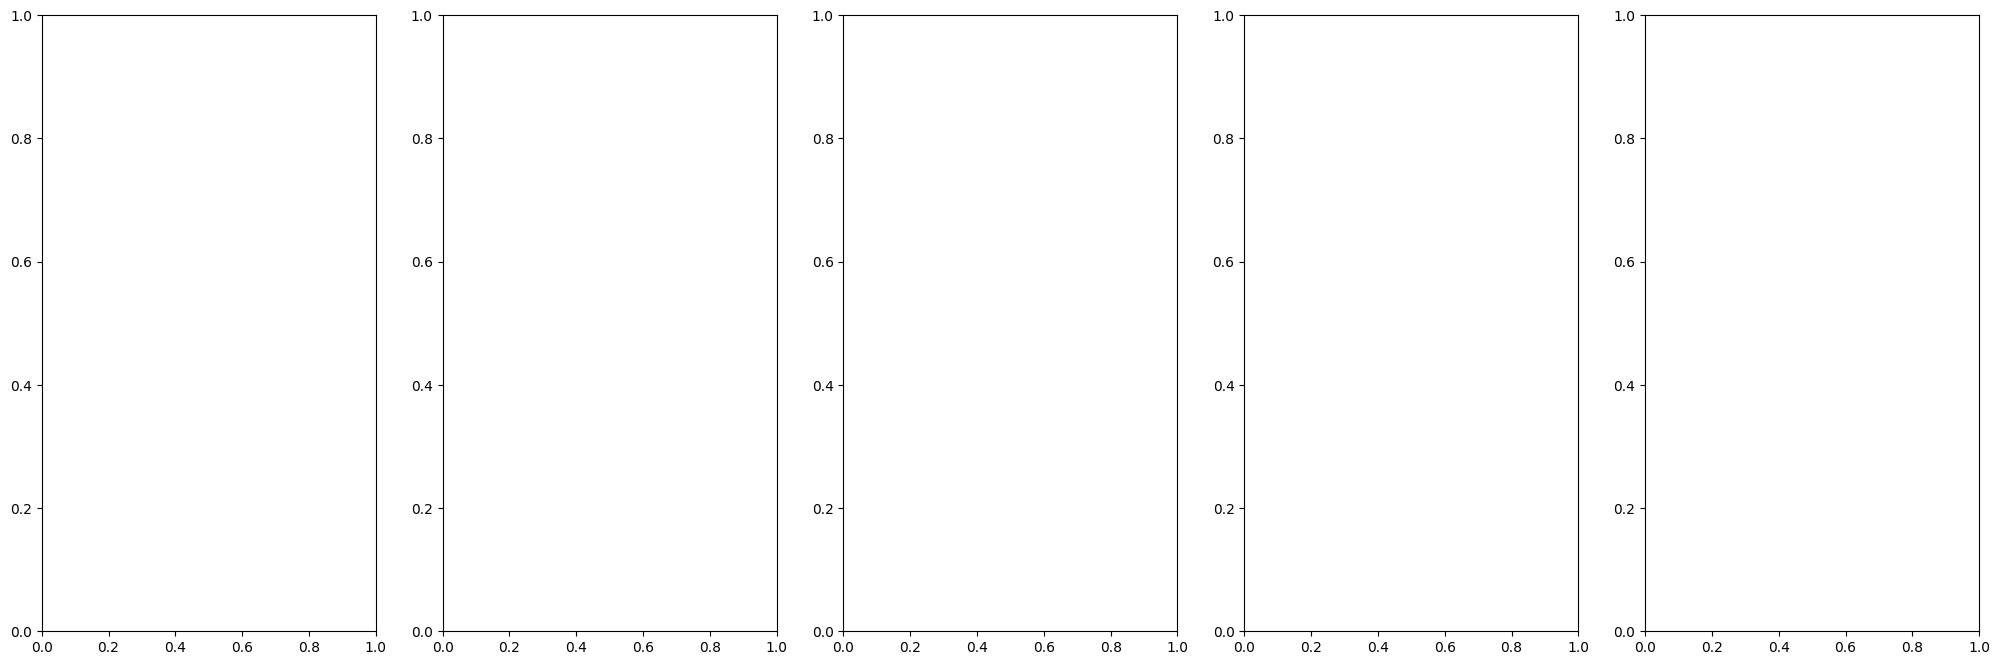

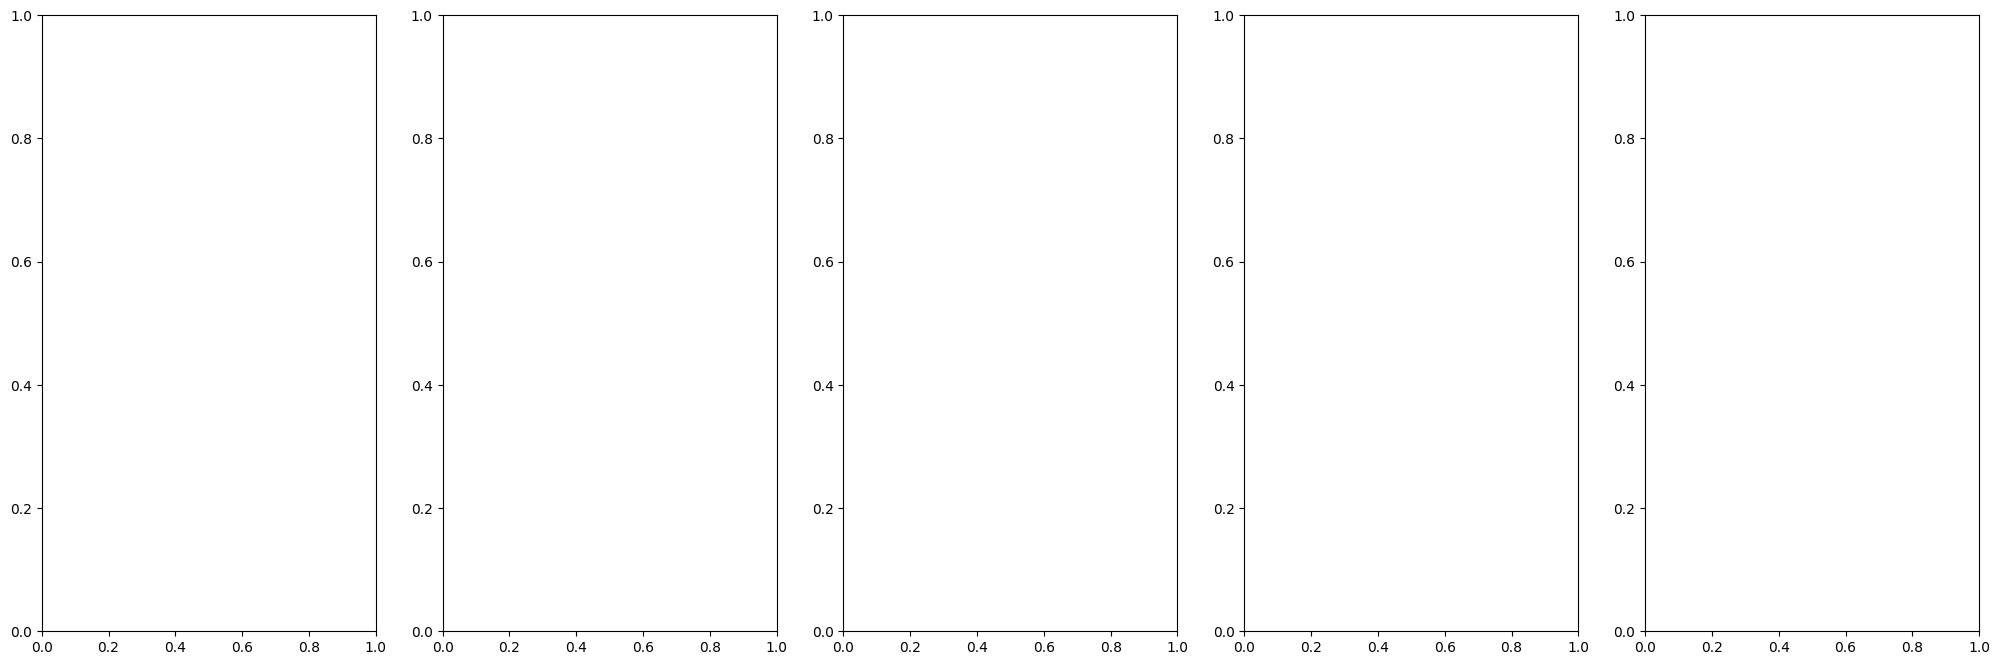

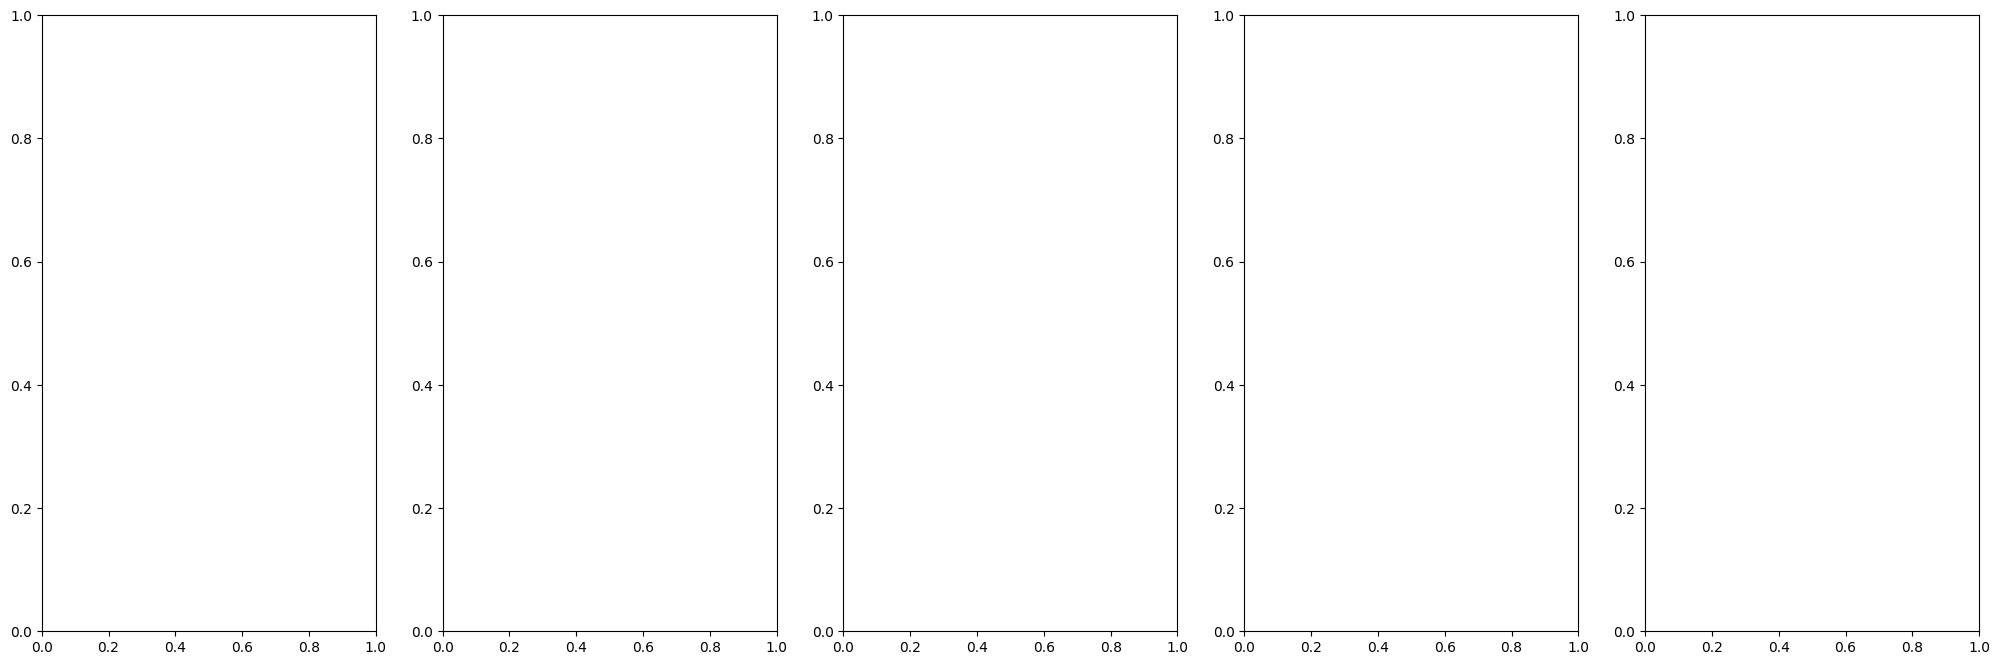

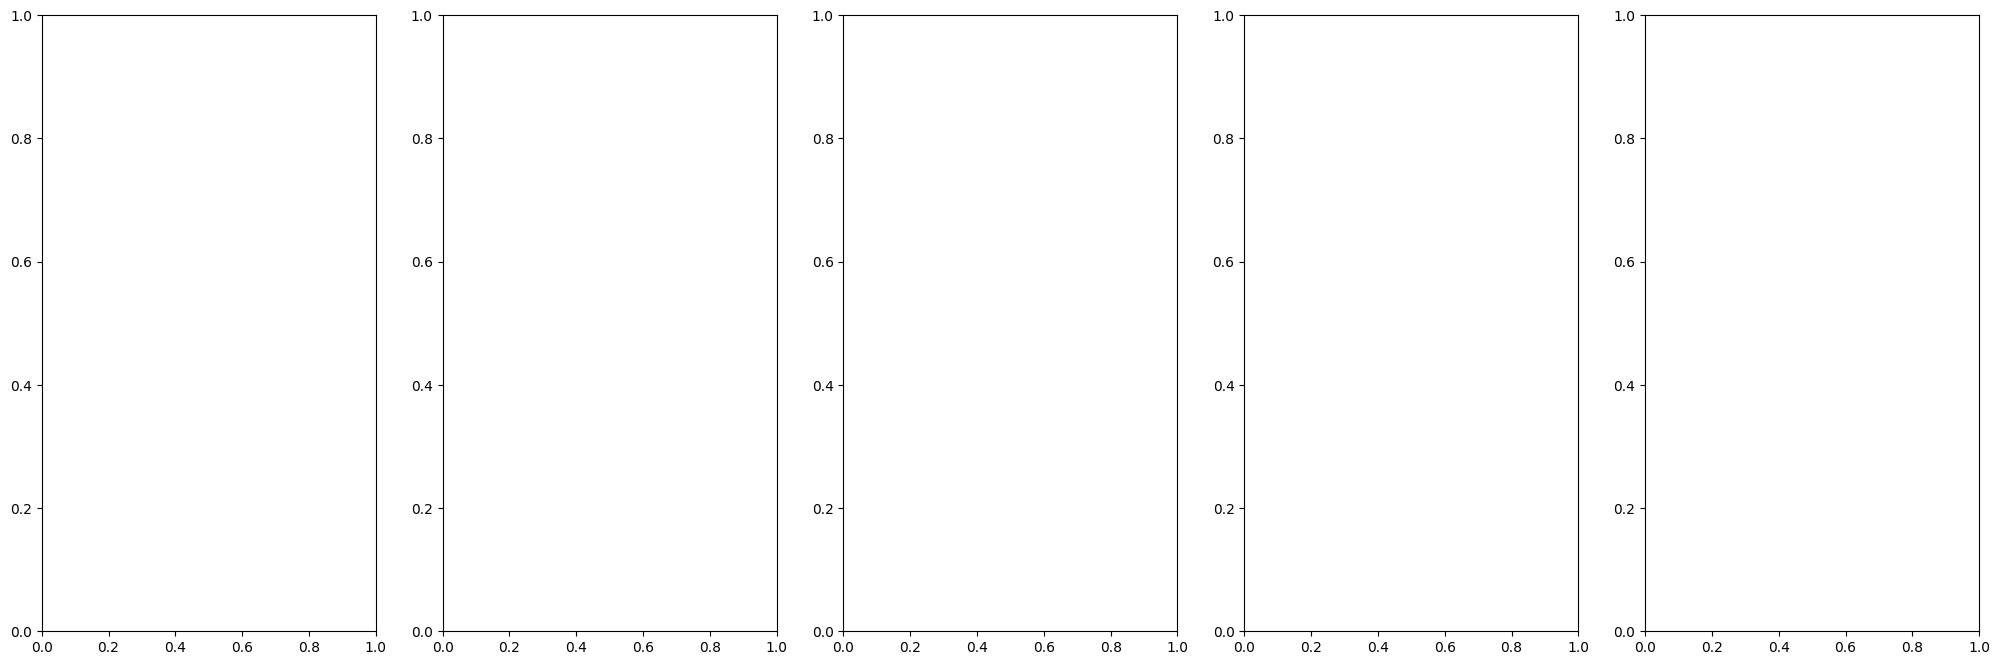

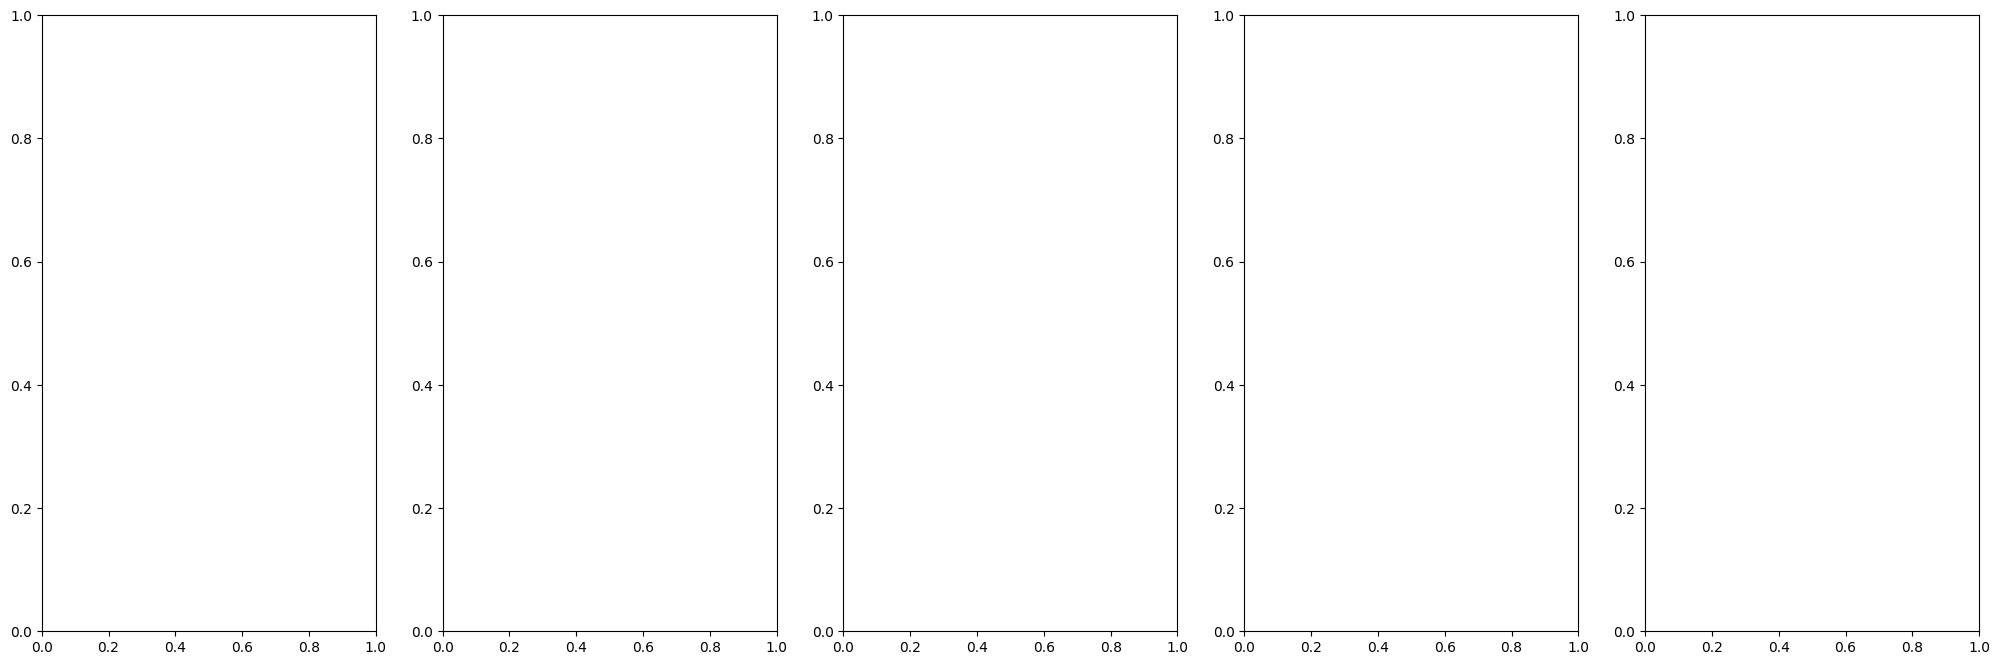

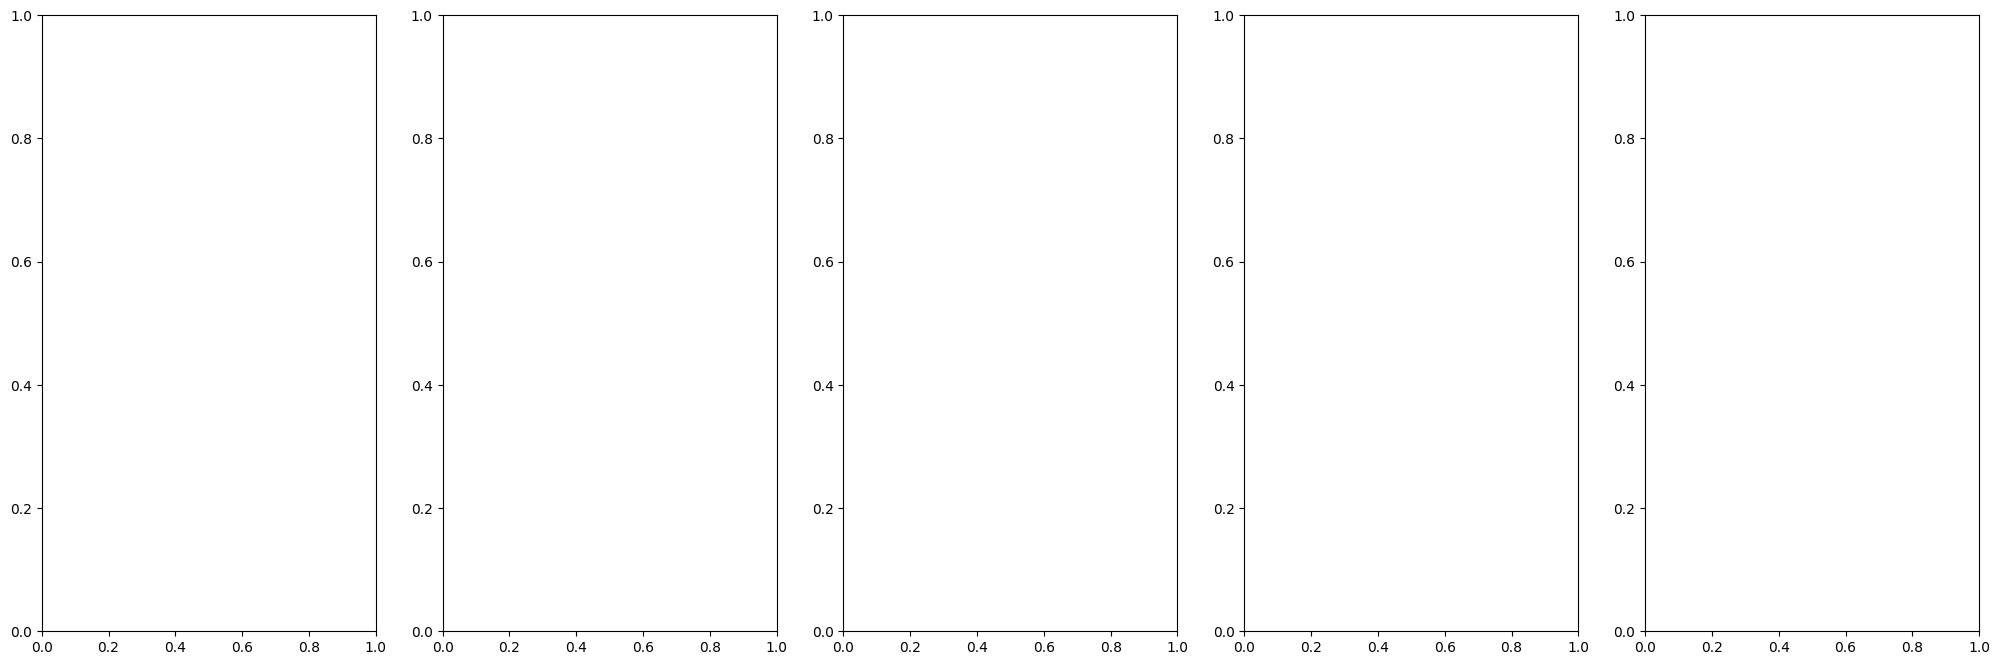

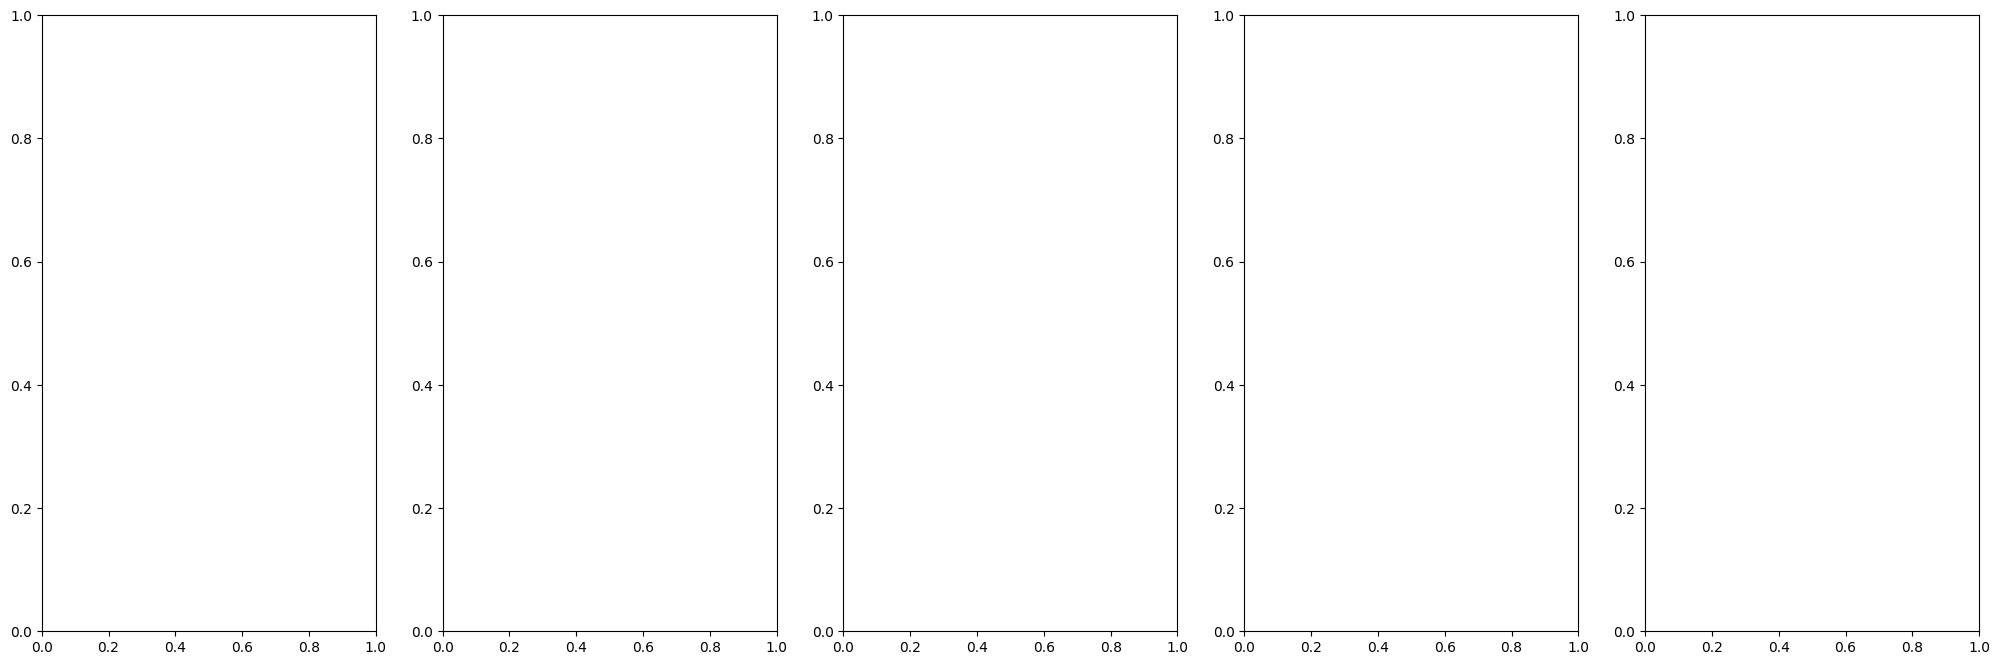

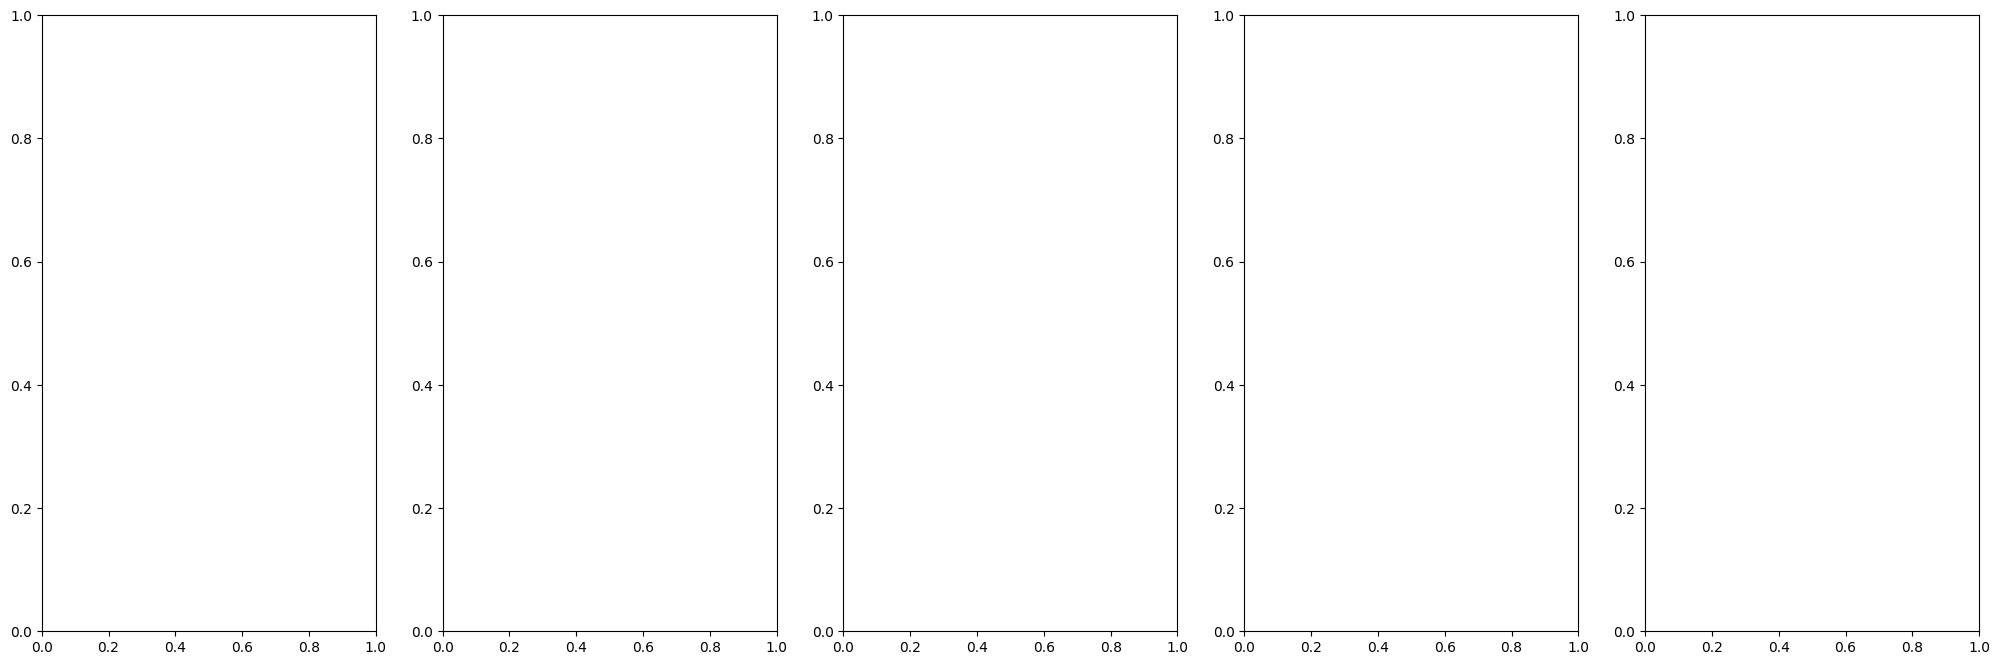

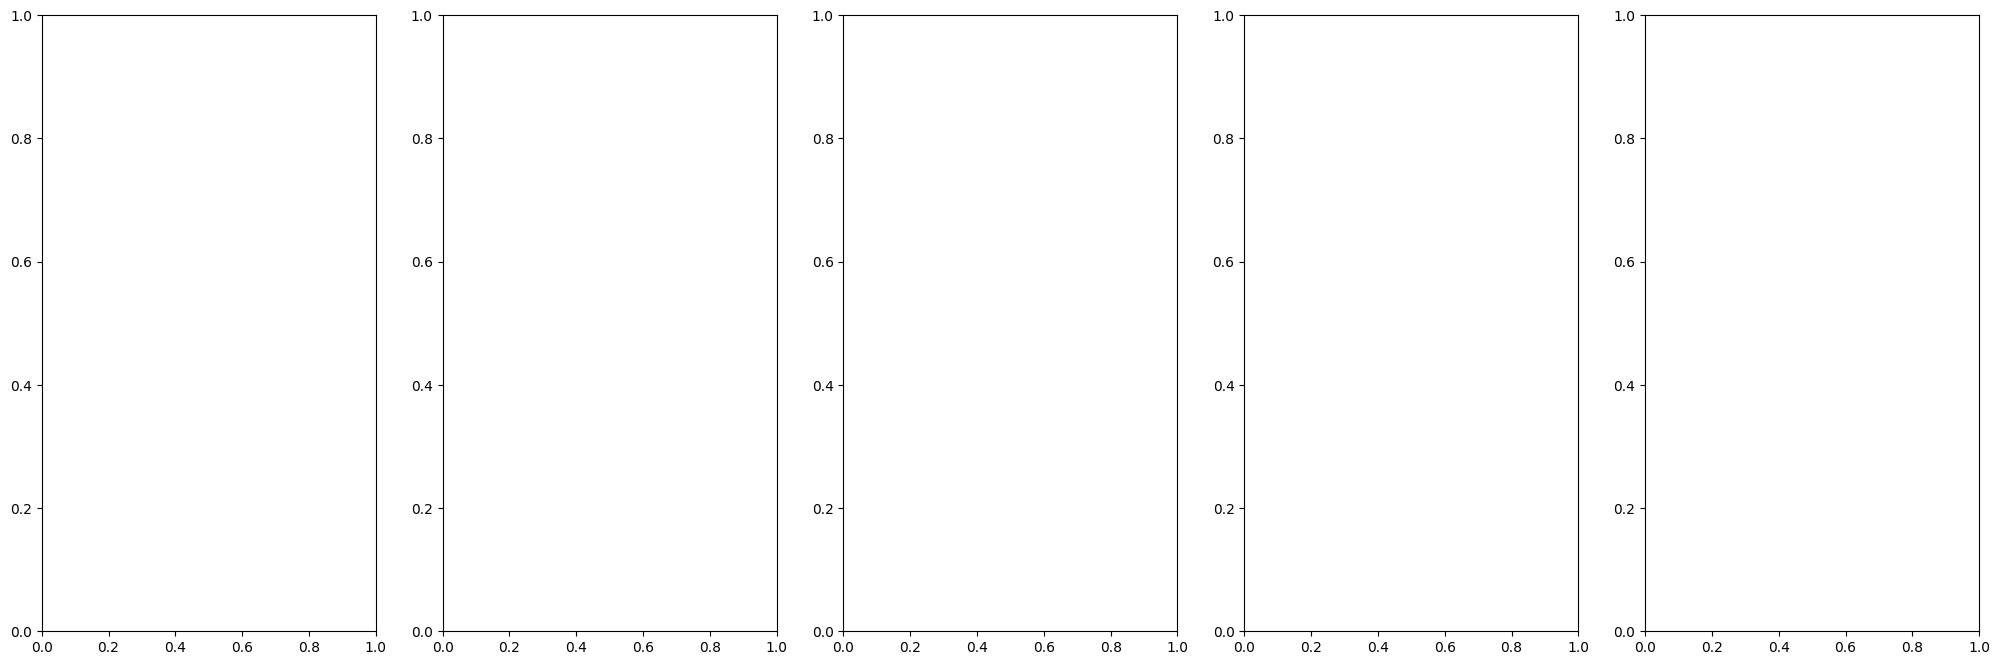

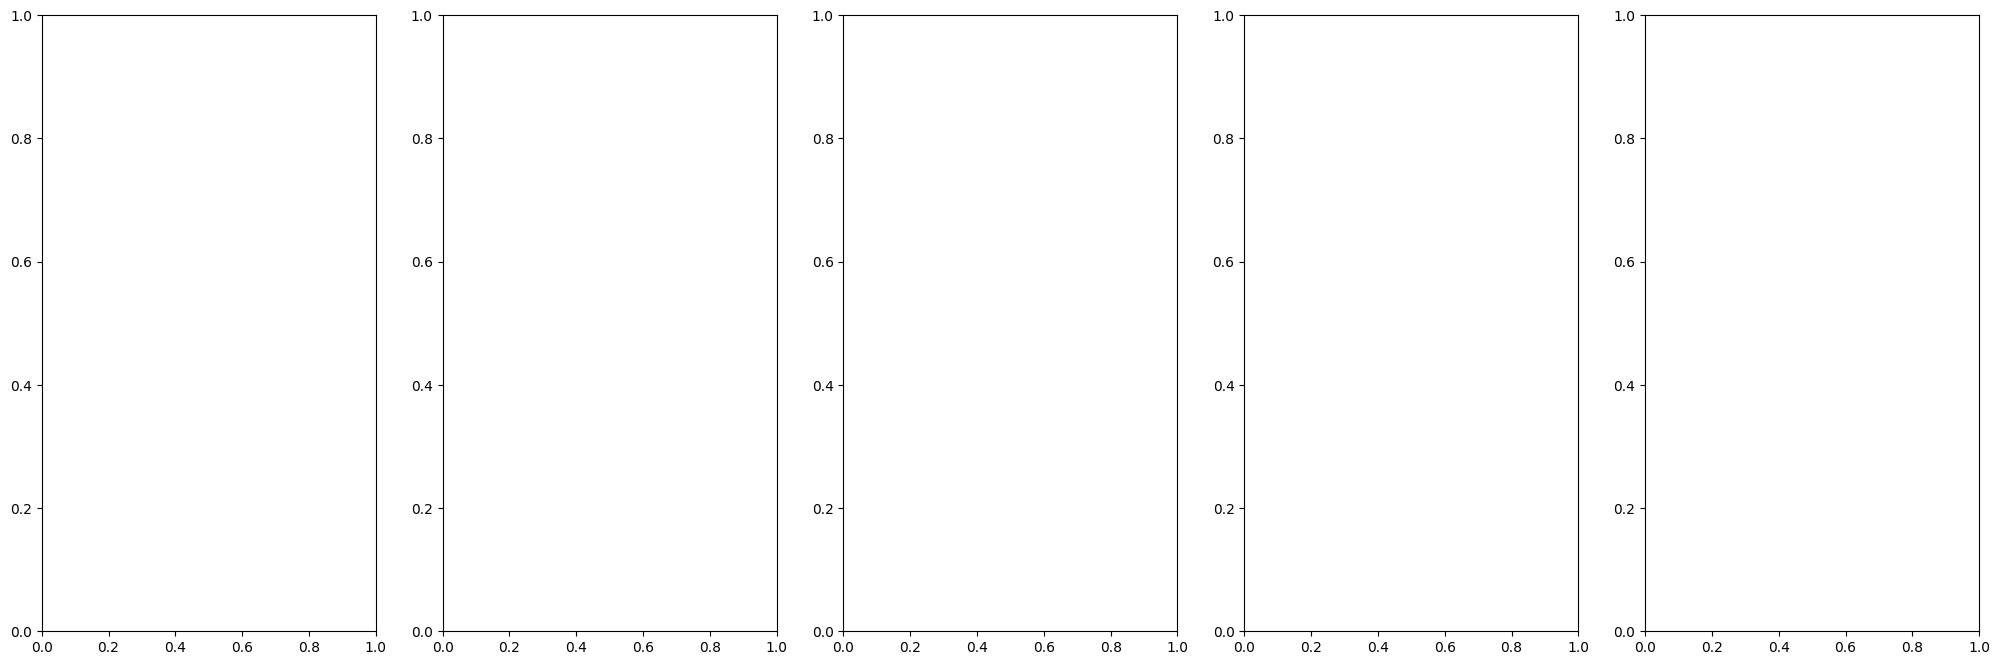

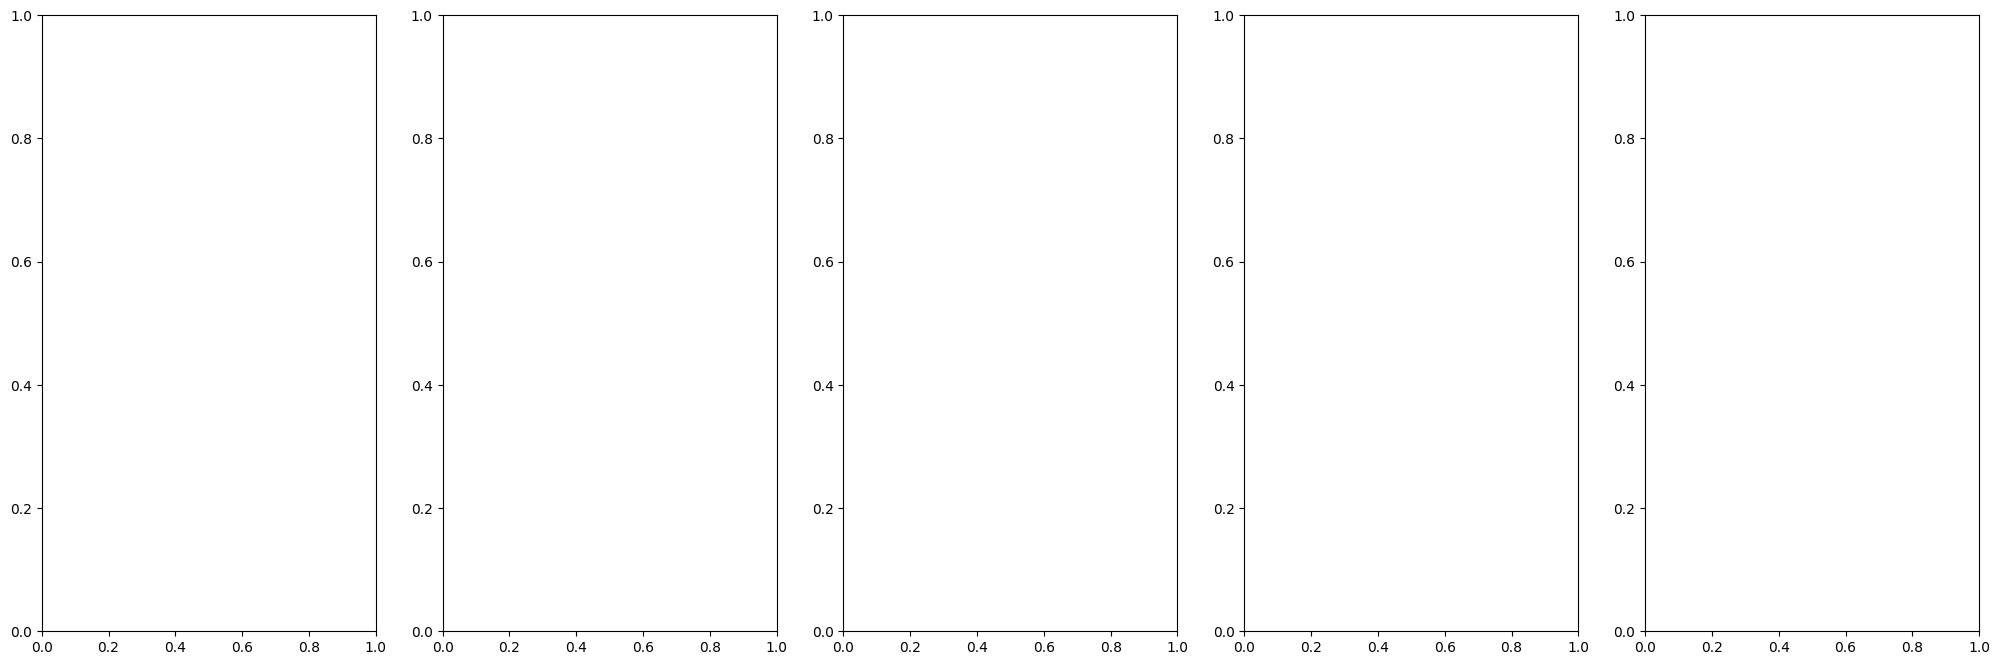

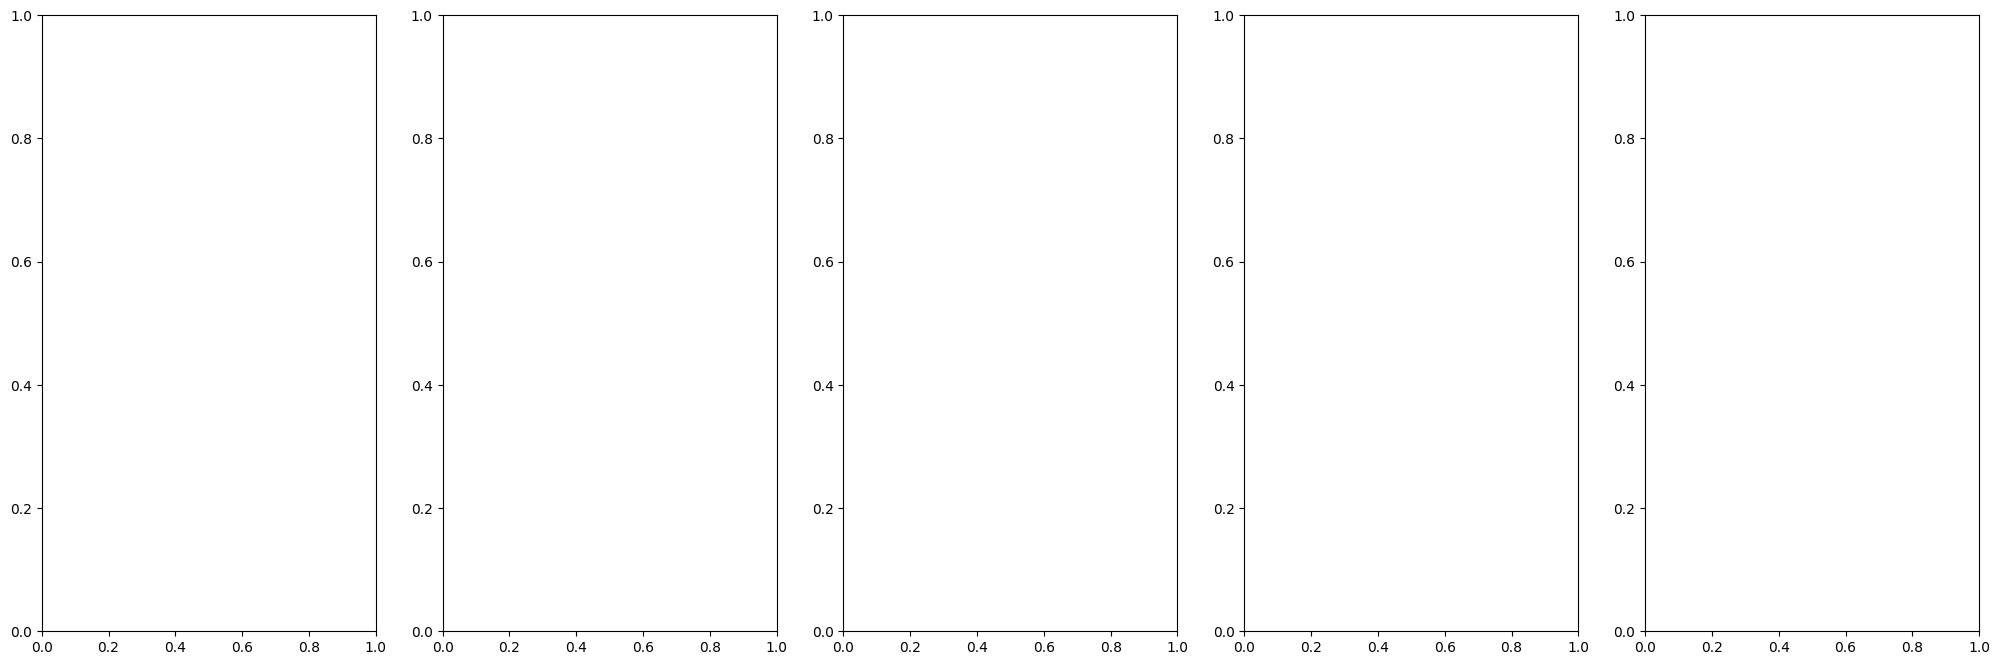

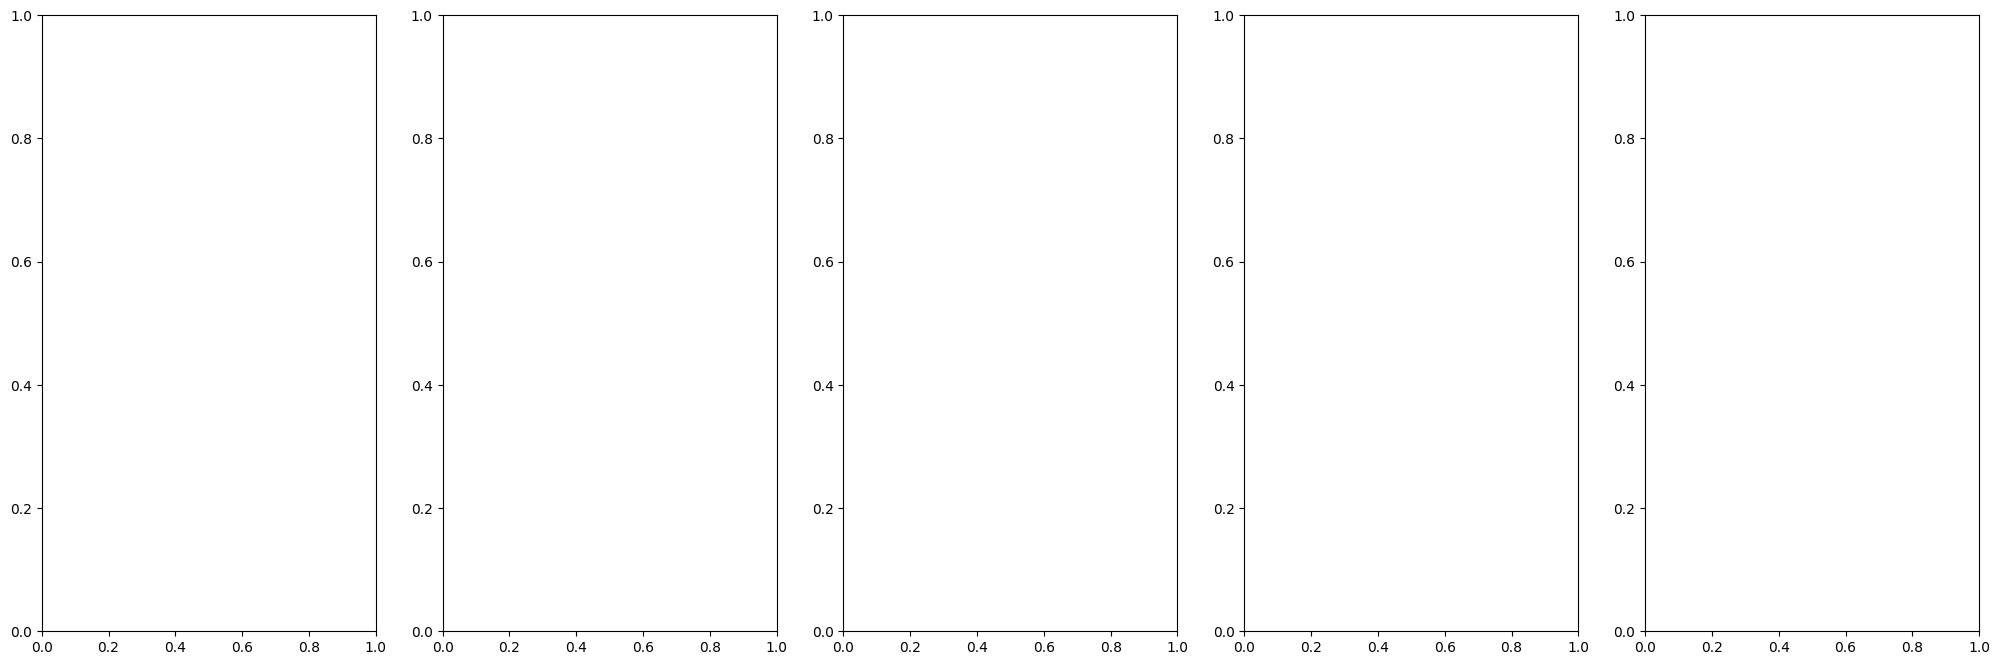

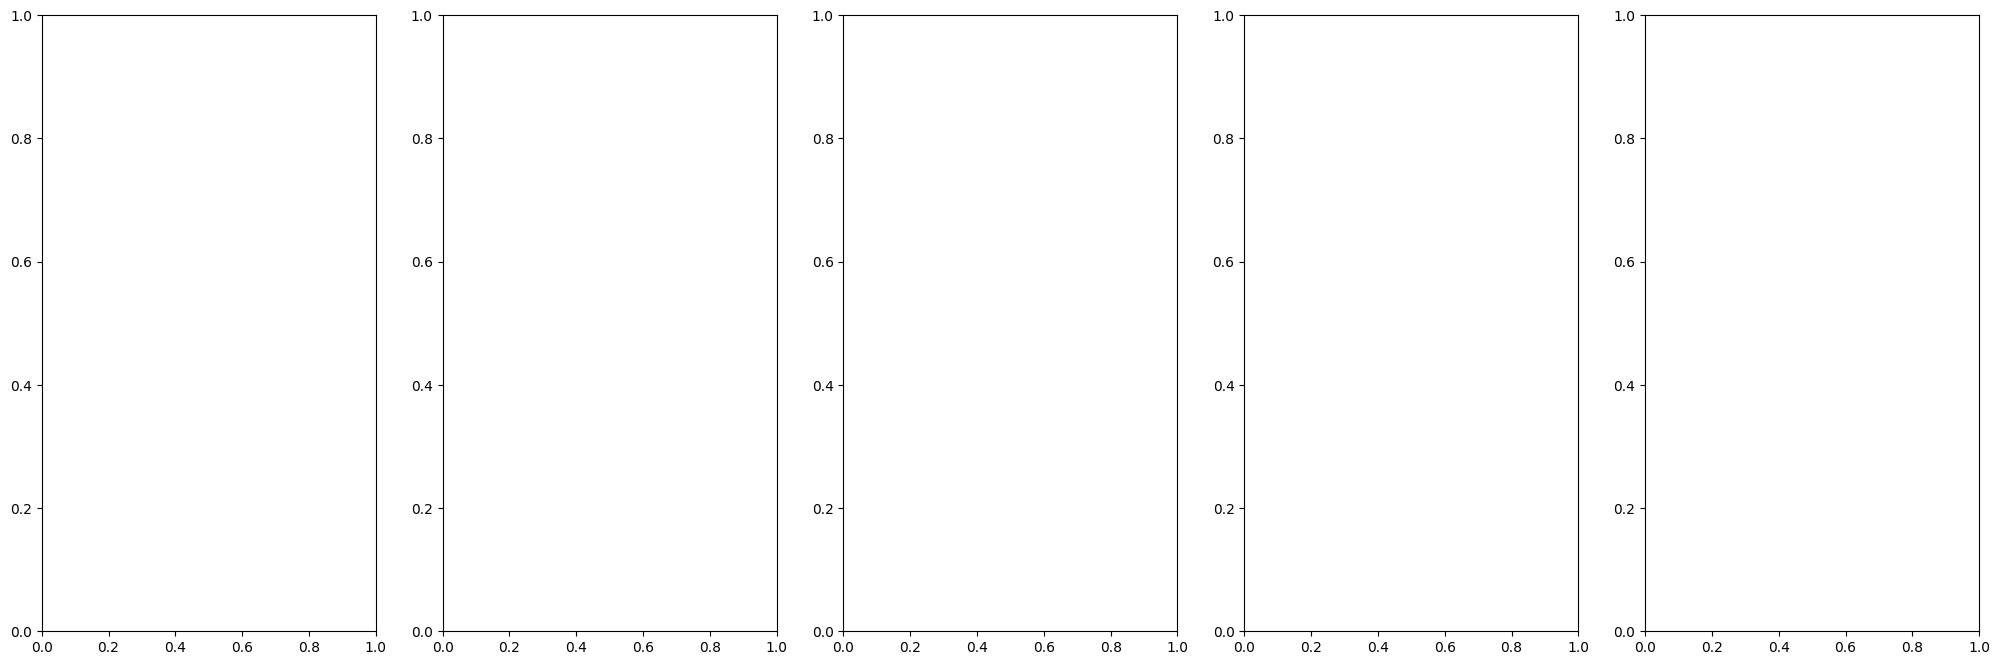

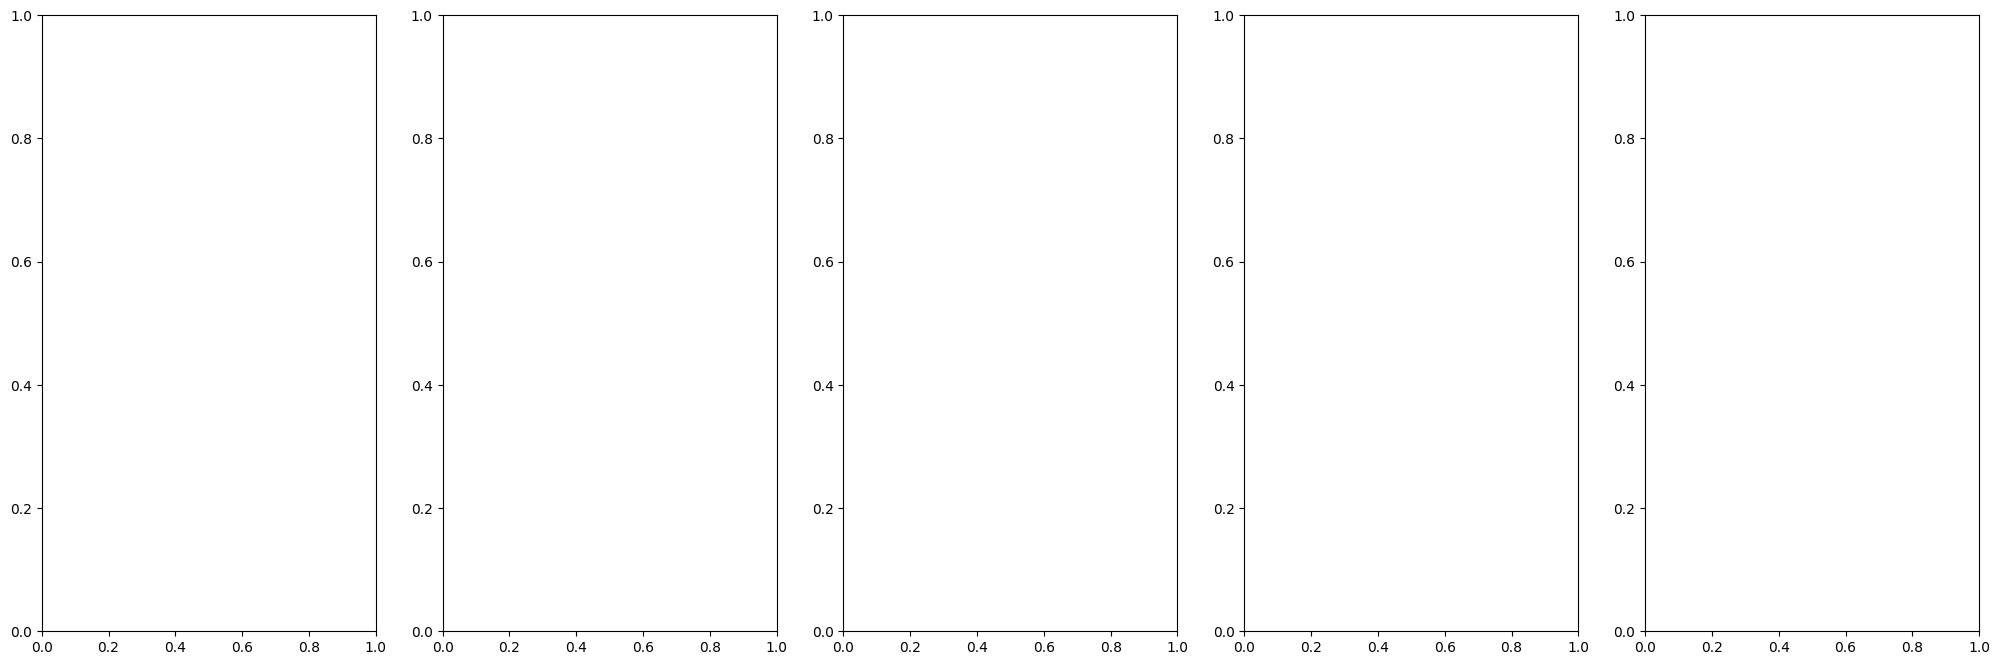

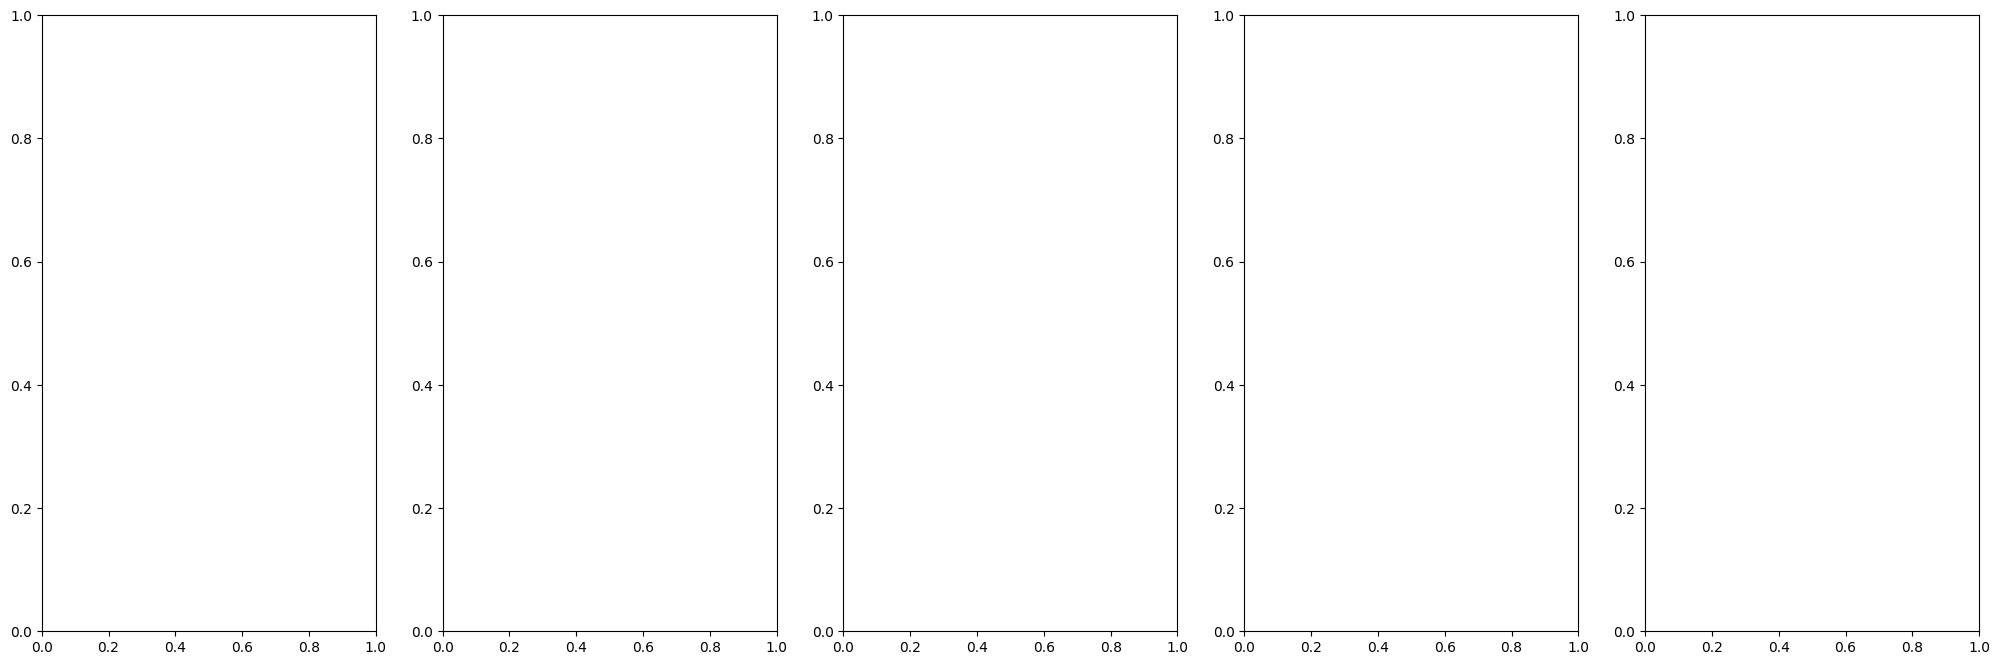

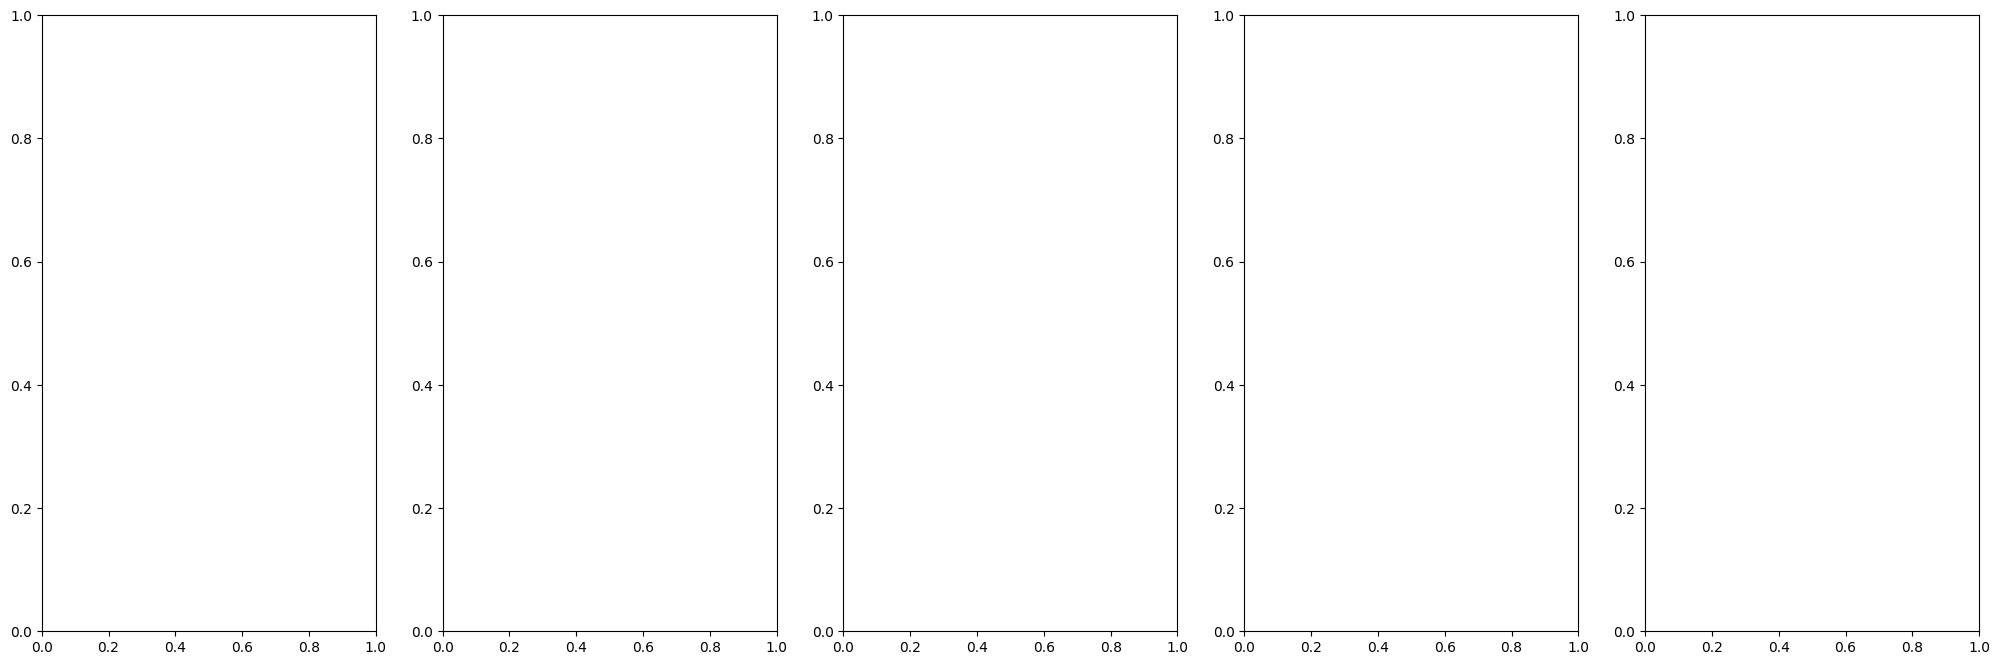

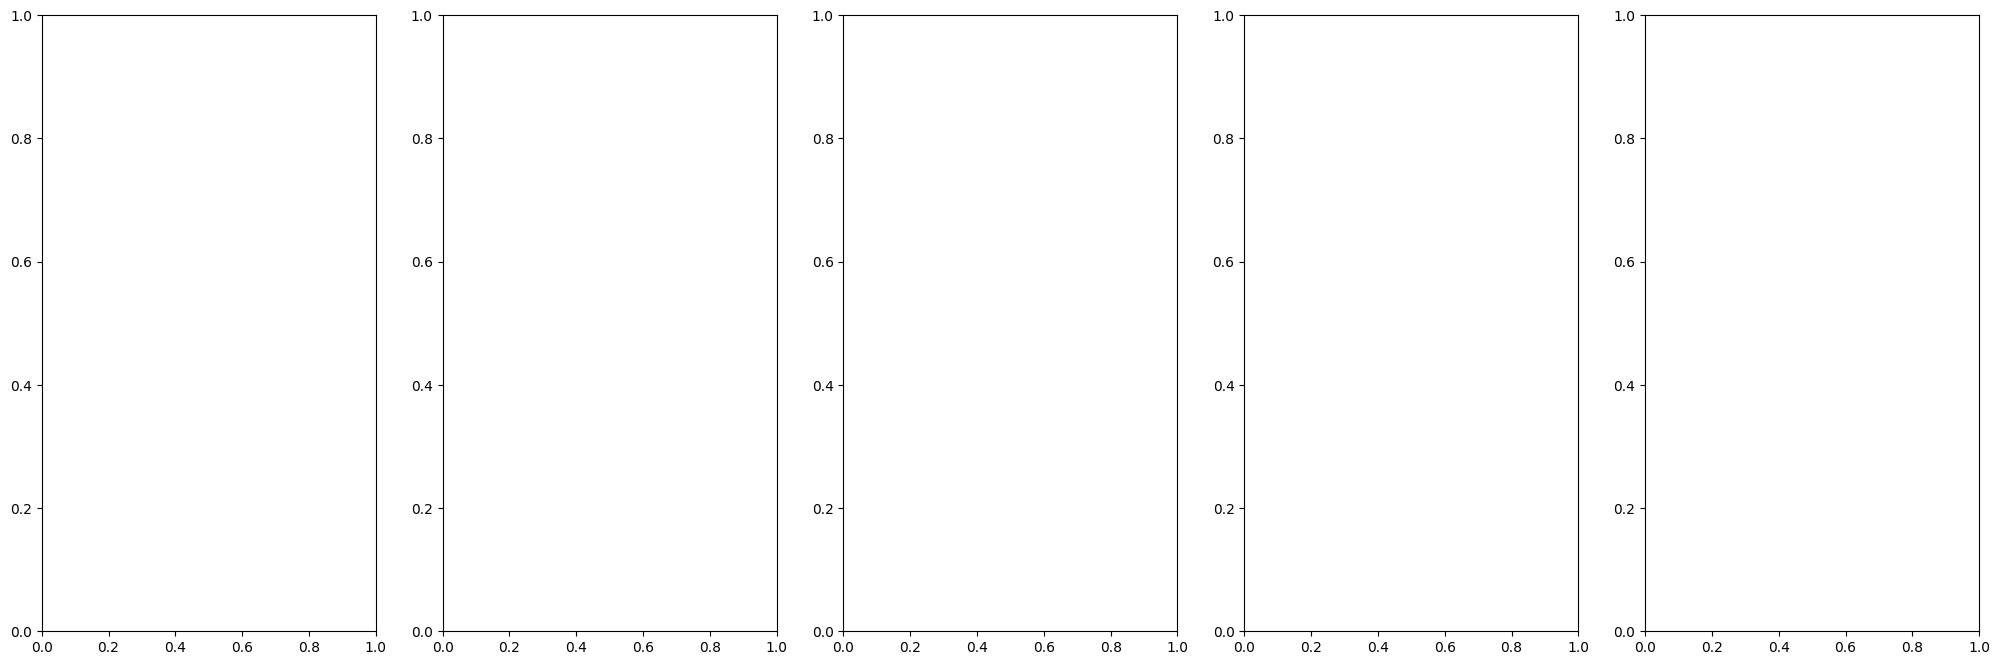

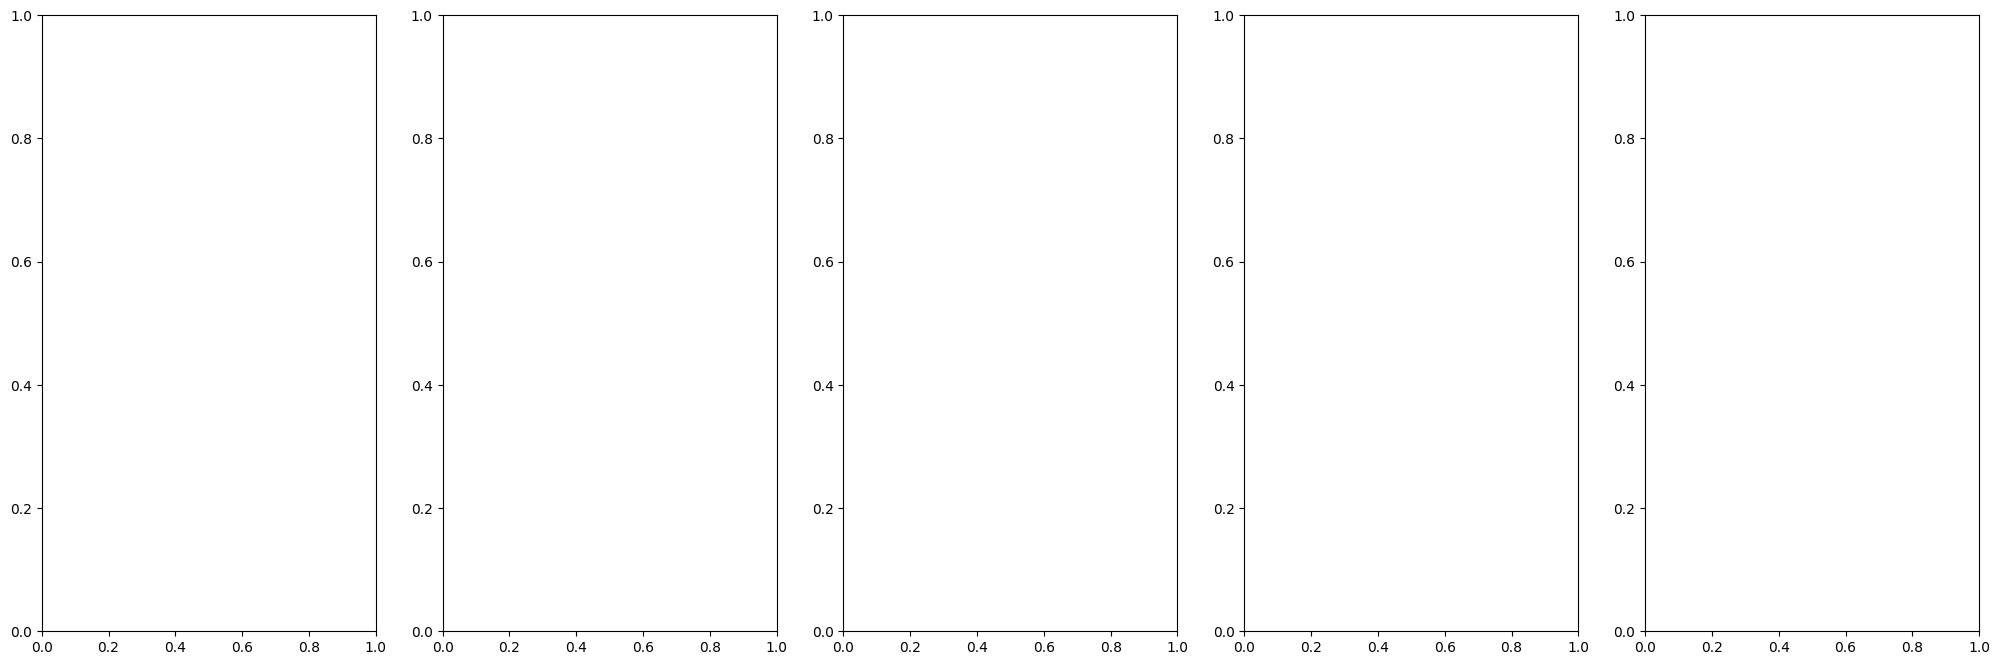

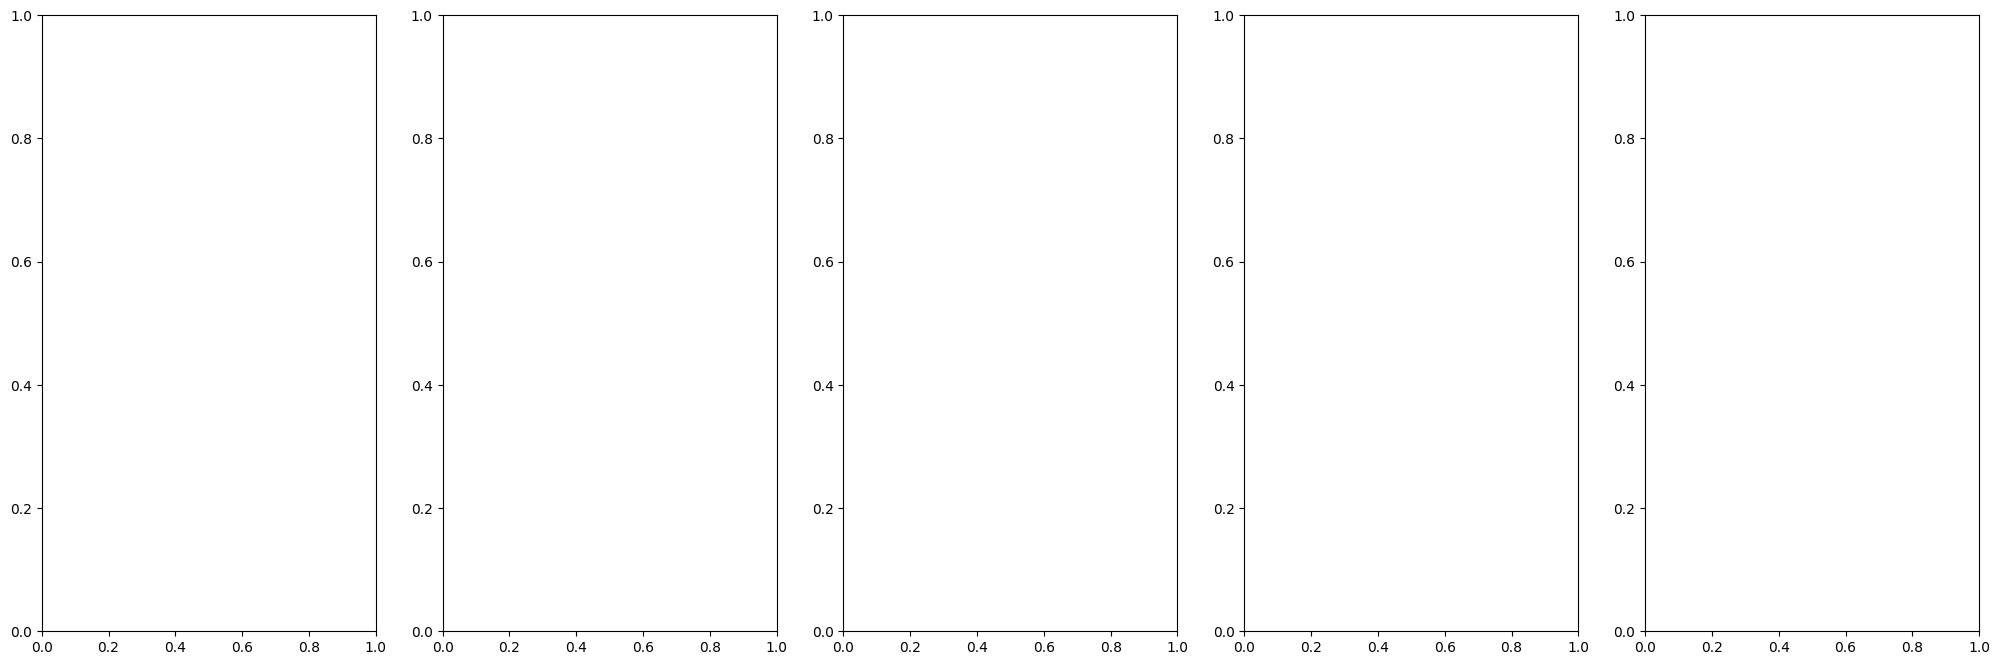

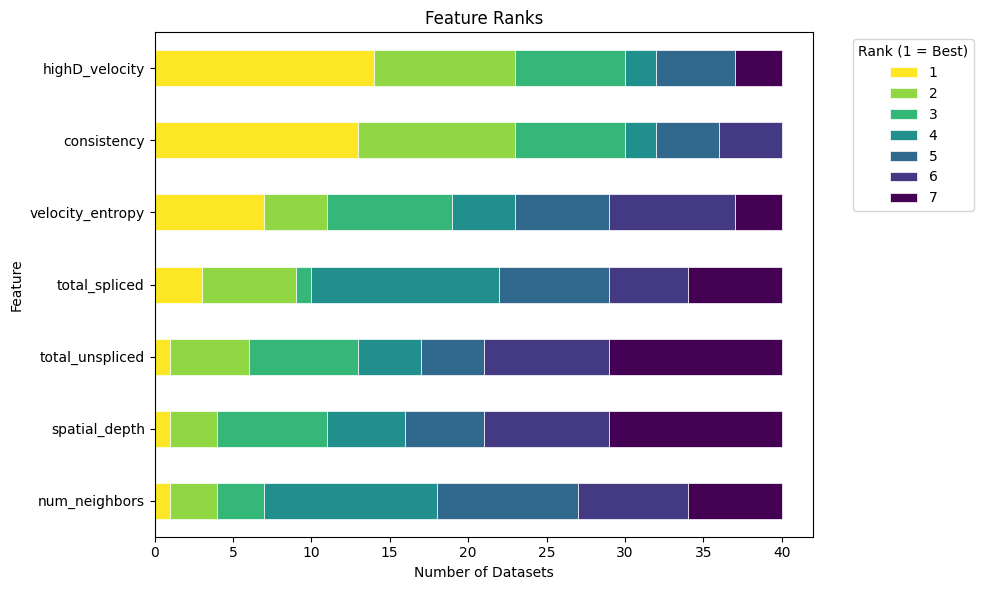

In [12]:
imp_df, scores_df = run_rf_classifier(datasets, use_cell_position=True, use_extra=True)

print(f"\nFeature Importances:")
print(imp_df.to_string(index=False))

print(f"\nMean CV Scores:")
print(scores_df.mean()) 
plot_feature_ranks(imp_df, title="Feature Ranks")


### Do it only for some cells (top/bottom 200)

In [15]:
def run_rf_classification_part(datasets, use_cell_position, extra_features, output_dir="/mnt/volume/Johanna_Velotest/results/ml_within/"):
    responses = {}
    scores = {}
    importance = pd.DataFrame()
    
    for name, path in datasets.items():
        with open(path, "r") as f:
            config = yaml.safe_load(f)
            
        print(f"Processing dataset: {name} (Top/Bottom 200)")
        
        adata = sc.read(config['path'])
        basis = config['basis']
        cluster = config['cluster']
        n_neighbors = config['number_neighbors_to_sample_from']

        upper = adata.obsm['upper_max_neighbors']
        best = adata.uns['best_embedding']
        non_empty_indices = adata.uns['non_empty_indices']
        
        adata_copy = adata[non_empty_indices, :].copy()
        upper = upper[non_empty_indices]
        distances = np.subtract(upper, best)

        X, features = prepare_feature_matrix(adata_copy, 
                                             cluster=cluster, 
                                             basis=basis, 
                                             n_neighbors=n_neighbors,
                                             use_cell_position=use_cell_position,
                                             extra_features=extra_features)
        
        # Subset to the top/bottom 200 cells
        sorted_idx = np.argsort(distances)
        bottom_200_idx = sorted_idx[:200]
        top_200_idx = sorted_idx[-200:]

        extreme_indices = np.concatenate([bottom_200_idx, top_200_idx])
        X_extremes = X[extreme_indices, :]
        y_extremes = np.concatenate([np.zeros(200), np.ones(200)])
        
        clf = ensemble.RandomForestClassifier(random_state=0, 
                                            n_estimators=100,
                                            max_depth=10, 
                                            min_samples_leaf=2,
                                            max_features='sqrt')

        # Use manual CV to better extract feature importance
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        fold_importances = []
        fold_scores = []
        shap_data = {
            'dataset_name': name,
            'features': features,
            'folds': []
        }

        for i, (train_idx, test_idx) in enumerate(cv.split(X_extremes, y_extremes)):
            X_train, X_test = X_extremes[train_idx, :], X_extremes[test_idx, :]
            y_train, y_test = y_extremes[train_idx], y_extremes[test_idx]
            
            clf.fit(X_train, y_train)
            fold_scores.append(clf.score(X_test, y_test))
            
            perm_imp = permutation_importance(clf, X_test, y_test, n_repeats=5, random_state=42, n_jobs=-1)
            fold_importances.append(perm_imp.importances_mean)

            explainer = shap.TreeExplainer(clf)
        
            shap_values = explainer.shap_values(X_test)

            # 3. Extract the correct matrix for the positive class (Class 1)
            if isinstance(shap_values, list):
                # Fallback for older SHAP versions (returns a list of arrays)
                plot_values = shap_values[1]
            elif len(shap_values.shape) == 3:
                # Newer SHAP versions (returns a 3D array: n_samples, n_features, n_classes)
                plot_values = shap_values[:, :, 1]
            else:
                # Fallback for regression or single-output models
                plot_values = shap_values

            # 4. Generate the summary plot
            shap_data['folds'].append({
                'fold_idx': i,
                'plot_values': plot_values,
                'X_test': X_test
            })
    
                
        shap_save_path = f"/mnt/volume/Johanna_Velotest/results/ml_within/{name}_200_SHAP_data.pkl"
        with open(shap_save_path, 'wb') as f:
            pickle.dump(shap_data, f)
            
        mean_importance = np.mean(fold_importances, axis=0)
        mean_importance_std = np.std(fold_importances, axis=0)
        mean_score = np.mean(fold_scores)
        std_score = np.std(fold_scores)
        
        current_df = pd.DataFrame({
            'Feature': features,
            f'{name}_mean': mean_importance,
            f'{name}_std': mean_importance_std
        })
        
        if importance.empty:
            importance = current_df
        else:
            importance = importance.merge(current_df, on='Feature', how='outer')

        scores[f'{name}_mean'] = mean_score
        scores[f'{name}_std'] = std_score
        responses[name] = y_extremes 
        
        #save_path = f"{output_dir}RF.npz"
        #np.savez_compressed(save_path, X=X_extremes, response=y_extremes, features=features)

    df_scores = pd.DataFrame([scores]) 
    
    importance.to_csv(f"{output_dir}RF_200_importance.csv", index=False)
    df_scores.to_csv(f"{output_dir}RF_200_scores.csv", index=False)

    return importance, df_scores

Processing dataset: Pancreas_dynamical (Top/Bottom 200)
Processing dataset: Pancreas_stochastic (Top/Bottom 200)
Processing dataset: Dentate_gyrus (Top/Bottom 200)
Processing dataset: Gastrulation_erythroid (Top/Bottom 200)
Processing dataset: Bone_marrow (Top/Bottom 200)
Processing dataset: PBMC (Top/Bottom 200)
Processing dataset: Covid (Top/Bottom 200)
Processing dataset: Retinal_development (Top/Bottom 200)
Processing dataset: Human_HSC (Top/Bottom 200)
Processing dataset: RPE_1 (Top/Bottom 200)
Processing dataset: Hindbrain_mouse (Top/Bottom 200)
Processing dataset: Oligodendrocyte_mouse (Top/Bottom 200)
Processing dataset: Bone_marrow_mouse (Top/Bottom 200)
Processing dataset: Cerebral_cortex_human (Top/Bottom 200)
Processing dataset: Hematopoiesis_mouse (Top/Bottom 200)
Processing dataset: Spermatogenisis (Top/Bottom 200)
Processing dataset: Old_brain (Top/Bottom 200)
Processing dataset: Prefrontal_cortex (Top/Bottom 200)
Processing dataset: Intestinal_organoids (Top/Bottom 200)

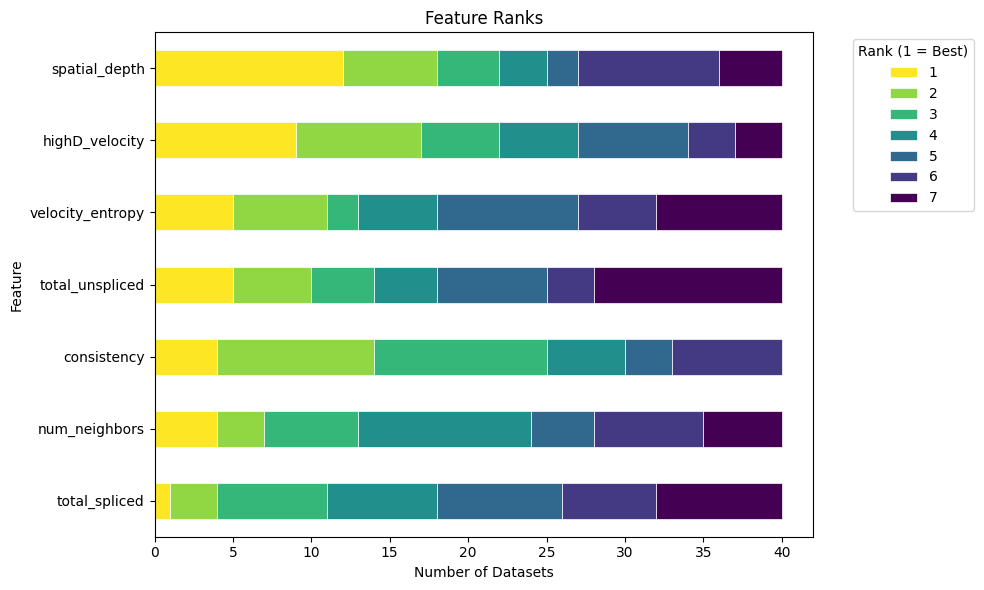

In [16]:
imp_df_part, scores_df_part = run_rf_classification_part(datasets, use_cell_position=True, extra_features=True)
print("Feature Importances:")
print(imp_df_part.to_string(index=False))

print("Mean CV Scores:")
print(scores_df_part.mean())
plot_feature_ranks(imp_df_part, title="Feature Ranks")
